# EDA de los datasets de entrenamiento (destilación → QLoRA)

**Tesis:** Pipeline multiagente de IA para el ciclo de vida del requerimiento de software (UNI).
**Objetivo de este notebook:** describir el dataset con el que se entrenaron los 5 adaptadores QLoRA (`jrosado1974/tesis-sft-v2`, público): de dónde viene, cuántos ejemplos tiene, cómo se reparten, qué longitud tienen, qué contienen y si hay fuga entre particiones o con el piloto.

Se ejecuta en Google Colab o en local sin GPU (solo descarga datos públicos). Tiempo: ~2 minutos.

| Paso | Qué se revisa |
|---|---|
| 1 | Linaje: de qué datasets intermedios sale `tesis-sft-v2` |
| 2 | Tamaño por agente y partición (train / val / test) |
| 3 | Longitud en tokens (tokenizador de Qwen3-8B) y efecto del límite de longitud del entrenamiento |
| 4 | Contenido de las salidas (historias, ADRs, endpoints, casos, pipelines) |
| 5 | Calidad: validez contra el JSON Schema de cada agente |
| 6 | Fuga: requerimientos repetidos entre particiones o con el piloto (SIM-P05) |

In [1]:
# Dependencias (en Colab ya vienen pandas y matplotlib)
!pip -q install huggingface_hub tokenizers jsonschema

In [2]:
import json, collections, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download, hf_hub_download
from tokenizers import Tokenizer

DATASET = "jrosado1974/tesis-sft-v2"          # dataset público
AGENTES = ["product-analyst-agent", "solution-architect-agent", "api-designer-agent",
           "test-case-generator-agent", "cicd-pipeline-agent"]
DOMINIO = {"product-analyst-agent": "Discovery", "solution-architect-agent": "Arquitectura",
           "api-designer-agent": "Ingeniería", "test-case-generator-agent": "Calidad", "cicd-pipeline-agent": "DevOps"}
ruta = snapshot_download(DATASET, repo_type="dataset")
filas = []
for ag in AGENTES:
    for split in ("train", "val", "test"):
        with open(f"{ruta}/{ag}/{split}.jsonl", encoding="utf-8") as f:
            for l in f:
                r = json.loads(l); r["agente"] = ag; r["split"] = split; filas.append(r)
df = pd.DataFrame(filas)
print("Ejemplos cargados:", len(df)); print("Campos de cada ejemplo:", list(filas[0].keys()))

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Fetching 19 files: 100%|██████████| 19/19 [00:00<00:00, 2451.53it/s]

Ejemplos cargados: 1013
Campos de cada ejemplo: ['req_id', 'rounds', 'f5', 'messages', 'origen', 'agente', 'split']


## 1. Linaje del dataset

Los ejemplos se generaron por **destilación**: el modelo maestro `Qwen/Qwen3-32B-AWQ` ejecutó el pipeline sobre requerimientos sintéticos (`scripts/gen_seeds.py`, distintos de los 30 del piloto) y **governance** (reglas deterministas) aceptó o rechazó cada salida. Solo las salidas aprobadas son ejemplos de entrenamiento.

| Dataset | Origen | Ejemplos | Acceso |
|---|---|---|---|
| `tesis-sft-pilot` | Prueba con 6 requerimientos | 18 | privado |
| `tesis-sft` | Tanda 1 (75 requerimientos) | 253 (+229 rechazados) | privado |
| `tesis-sft-r2` | Tanda 2 (194 requerimientos) | 912 (+187 rechazados) | privado |
| `tesis-sft-final` | Fusión de tandas 1 y 2 | 1 165 | privado |
| **`tesis-sft-v2`** | Re-filtrado con governance v2 (852) + 161 de DevOps regenerados por el maestro | **1 013** | **público** |

Fuente de las cifras: `runs/MANIFEST.md` del repositorio.

## 2. Tamaño por agente y partición

split,train,val,test,total
Discovery (product-analyst-agent),211,29,24,264
Arquitectura (solution-architect-agent),145,20,18,183
Ingeniería (api-designer-agent),182,28,22,232
Calidad (test-case-generator-agent),136,23,14,173
DevOps (cicd-pipeline-agent),136,16,9,161
TOTAL,810,116,87,1013


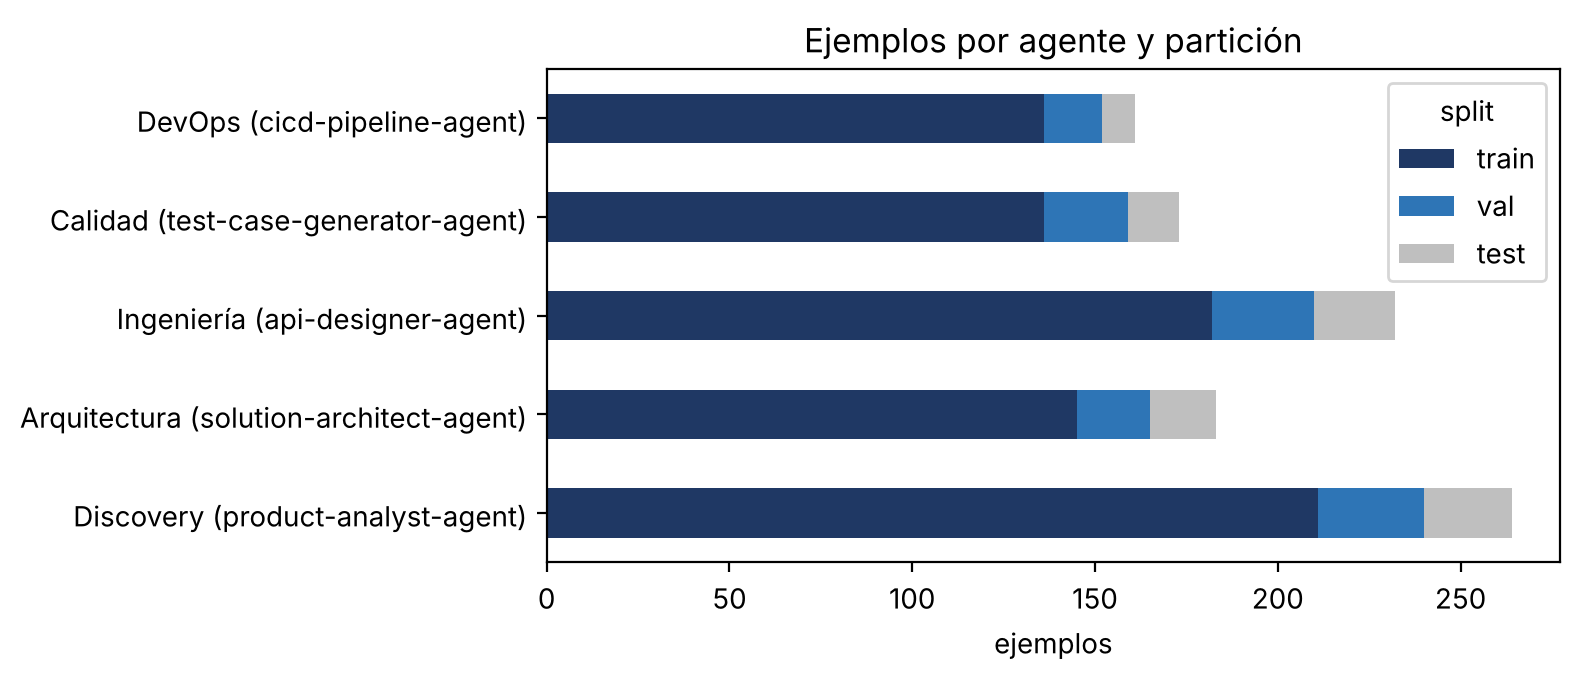

In [3]:
tabla = df.pivot_table(index="agente", columns="split", values="req_id", aggfunc="count").reindex(AGENTES)[["train", "val", "test"]]
tabla["total"] = tabla.sum(axis=1); tabla.loc["TOTAL"] = tabla.sum()
tabla.index = [DOMINIO.get(i, i) + (f" ({i})" if i in DOMINIO else "") for i in tabla.index]
display(tabla)
ax = tabla.drop("TOTAL")[["train", "val", "test"]].plot.barh(stacked=True, figsize=(8, 3.5), color=["#1F3864", "#2E75B6", "#BFBFBF"])
ax.set_xlabel("ejemplos"); ax.set_title("Ejemplos por agente y partición"); plt.tight_layout(); plt.show()

**Lectura:** la partición *train* enseña, *val* vigila el sobreajuste durante el entrenamiento y *test* (87 casos) solo se usa al final para medir. DevOps tiene menos ejemplos porque sus salidas se regeneraron con reglas más estrictas.

## 3. Longitud en tokens (tokenizador de Qwen3-8B)

,prompt (mediana),salida (mediana),total (mediana)
agente,,,
product-analyst-agent,2108.0,562.0,2667.0
solution-architect-agent,5748.0,954.0,6724.0
api-designer-agent,5814.0,1092.0,6914.0
test-case-generator-agent,4931.0,1355.0,6440.0
cicd-pipeline-agent,7280.0,1719.0,9055.0


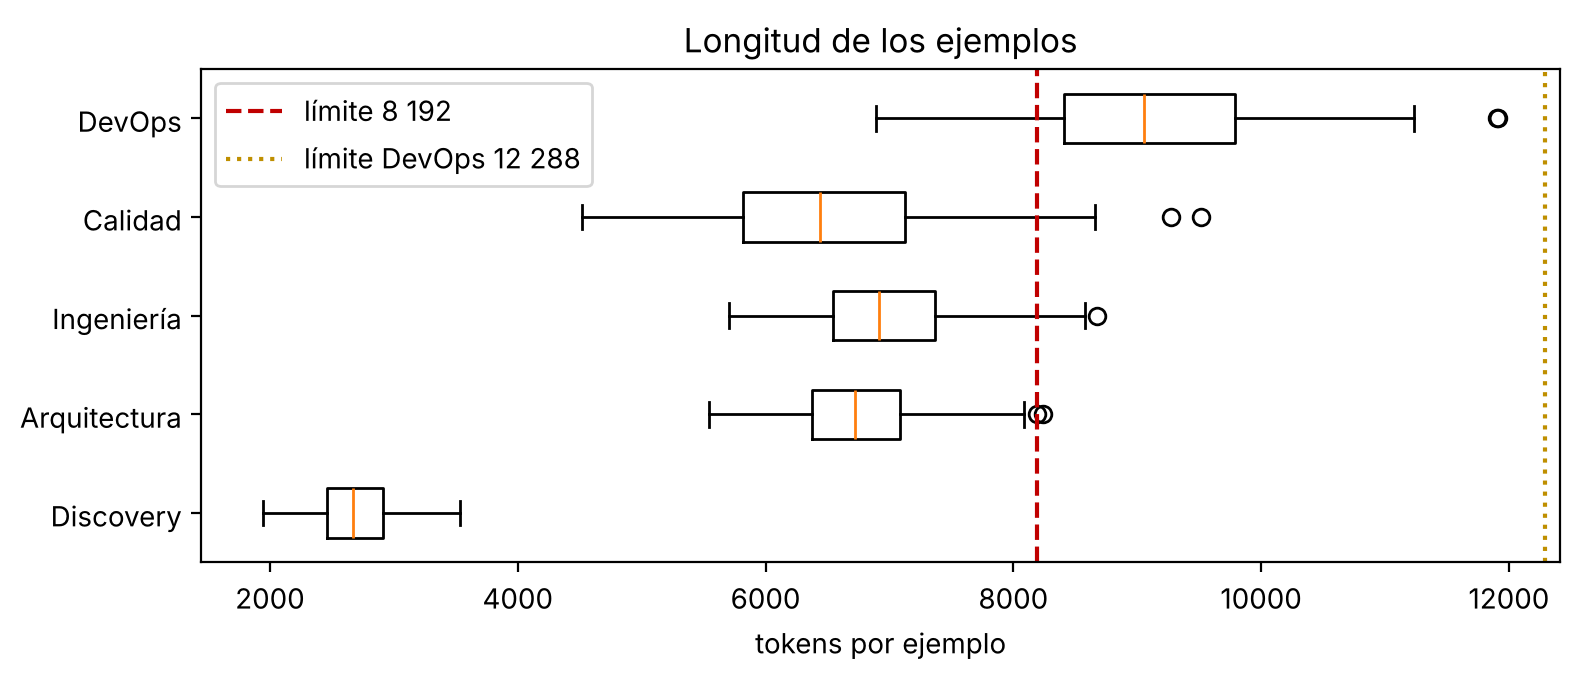

In [4]:
tok = Tokenizer.from_file(hf_hub_download("Qwen/Qwen3-8B", "tokenizer.json"))
def n_tokens(msgs):
    return len(tok.encode("\n".join(m["content"] for m in msgs)).ids)
df["tokens_prompt"] = df["messages"].apply(lambda m: n_tokens(m[:-1]))
df["tokens_salida"] = df["messages"].apply(lambda m: n_tokens(m[-1:]))
df["tokens_total"] = df["tokens_prompt"] + df["tokens_salida"]
resumen = df.groupby("agente")[["tokens_prompt", "tokens_salida", "tokens_total"]].median().reindex(AGENTES).round(0)
resumen.columns = ["prompt (mediana)", "salida (mediana)", "total (mediana)"]
display(resumen)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([df[df.agente == a]["tokens_total"] for a in AGENTES], tick_labels=[DOMINIO[a] for a in AGENTES], orientation="horizontal")
ax.axvline(8192, color="#C00000", ls="--", label="límite 8 192"); ax.axvline(12288, color="#BF8F00", ls=":", label="límite DevOps 12 288")
ax.set_xlabel("tokens por ejemplo"); ax.set_title("Longitud de los ejemplos"); ax.legend(); plt.tight_layout(); plt.show()

In [5]:
# Efecto del límite de longitud del entrenamiento (MAX_LEN = 8 192; DevOps 12 288)
lim = {a: (12288 if a == "cicd-pipeline-agent" else 8192) for a in AGENTES}
tr = df[df.split == "train"].copy()
tr["entra"] = tr.apply(lambda r: r.tokens_total <= lim[r.agente], axis=1)
efecto = tr.groupby("agente")["entra"].agg(en_dataset="count", usados_al_entrenar="sum").reindex(AGENTES)
efecto["descartados"] = efecto["en_dataset"] - efecto["usados_al_entrenar"]
display(efecto)
print("Train en el dataset:", efecto.en_dataset.sum(), "· usados al entrenar (aprox.):", efecto.usados_al_entrenar.sum())

,en_dataset,usados_al_entrenar,descartados
agente,,,
product-analyst-agent,211,211,0
solution-architect-agent,145,144,1
api-designer-agent,182,178,4
test-case-generator-agent,136,129,7
cicd-pipeline-agent,136,136,0


Train en el dataset: 810 · usados al entrenar (aprox.): 798


**Lectura:** el script de entrenamiento descarta los ejemplos que superan la longitud máxima (prompt con plantilla de chat + salida). Por eso se entrenó con algo menos que el total de *train* (en el registro de F3: 211 · 143 · 177 · 129 · 136 = 796). Este cálculo es aproximado porque aquí no se aplica la plantilla de chat completa.

## 4. Contenido de las salidas

In [6]:
def salida(r): return json.loads(r["messages"][-1]["content"])
def medir(r):
    o, a = salida(r), r["agente"]
    if a == "product-analyst-agent":  return {"elementos": len(o.get("historias", [])), "qué": "historias de usuario"}
    if a == "solution-architect-agent": return {"elementos": len(o.get("adrs", o.get("decisiones", []))), "qué": "ADRs"}
    if a == "api-designer-agent":     return {"elementos": len(o.get("endpoints", [])), "qué": "endpoints"}
    if a == "test-case-generator-agent": return {"elementos": len(o.get("casos", [])), "qué": "casos de prueba"}
    if a == "cicd-pipeline-agent":    return {"elementos": len(o.get("pipelines", [])), "qué": "pipelines"}
m = pd.DataFrame([medir(r) | {"agente": r["agente"]} for _, r in df.iterrows()])
display(m.groupby(["agente", "qué"])["elementos"].describe()[["mean", "min", "50%", "max"]].round(1))

,,mean,min,50%,max
agente,qué,,,,
api-designer-agent,endpoints,3.0,1.0,3.0,6.0
cicd-pipeline-agent,pipelines,3.0,3.0,3.0,3.0
product-analyst-agent,historias de usuario,2.6,1.0,3.0,6.0
solution-architect-agent,ADRs,2.0,1.0,2.0,3.0
test-case-generator-agent,casos de prueba,5.8,1.0,5.0,18.0


**Lectura:** cada ejemplo es un artefacto completo (no una etiqueta). Por ejemplo, un `user_story_set` tiene varias historias con criterios Given/When/Then y un diseño de API, varios endpoints. Por eso la calidad se mide con criterios verificables (contrato y F5) y no con accuracy de clasificación.

## 5. Calidad: validez contra el JSON Schema de cada agente

In [7]:
import jsonschema
from referencing import Registry, Resource
BASE_RAW = "https://raw.githubusercontent.com/javierrosado/tesis/main/agents"
registro = Registry(retrieve=lambda uri: Resource.from_contents(json.loads(urllib.request.urlopen(uri).read())))  # resuelve contracts/*.json
validos = {}
for a in AGENTES:
    url = f"{BASE_RAW}/{a.replace('-agent', '')}/output.schema.json"
    esquema = json.loads(urllib.request.urlopen(url).read()); esquema["$id"] = url
    validador = jsonschema.Draft202012Validator(esquema, registry=registro)
    sub = df[df.agente == a]
    ok = sum(validador.is_valid(salida(r)) for _, r in sub.iterrows())
    validos[DOMINIO[a]] = f"{ok}/{len(sub)} ({100*ok/len(sub):.1f} %)"
pd.Series(validos, name="salidas válidas contra el esquema actual")

Discovery       264/264 (100.0 %)
Arquitectura    183/183 (100.0 %)
Ingeniería      232/232 (100.0 %)
Calidad         173/173 (100.0 %)
DevOps          161/161 (100.0 %)
Name: salidas válidas contra el esquema actual, dtype: str

**Lectura:** todos los ejemplos pasaron governance al generarse (contrato + F5 + procedencia). Si algún esquema evolucionó después en el repositorio, aquí aparecería como diferencia.

## 6. Fuga entre particiones y con el piloto

In [8]:
ids = {s: set(df[df.split == s]["req_id"]) for s in ("train", "val", "test")}
print("train ∩ test:", len(ids["train"] & ids["test"]), "| train ∩ val:", len(ids["train"] & ids["val"]), "| val ∩ test:", len(ids["val"] & ids["test"]))
piloto = [i for i in df["req_id"].unique() if str(i).startswith("SIM-P05")]
print("Requerimientos del piloto (SIM-P05) en el dataset:", len(piloto))
print("Requerimientos distintos en el dataset:", df["req_id"].nunique())

train ∩ test: 0 | train ∩ val: 0 | val ∩ test: 0
Requerimientos del piloto (SIM-P05) en el dataset: 0
Requerimientos distintos en el dataset: 264


**Lectura:** las particiones se hicieron por requerimiento (no por ejemplo), así que un mismo requerimiento no aparece en entrenamiento y prueba a la vez, y ninguno de los 30 requerimientos del piloto se usó para entrenar.

## Conclusión

- `tesis-sft-v2` tiene 1 013 ejemplos aprobados por governance, repartidos en 5 agentes y 3 particiones.
- La longitud de los ejemplos explica el límite de 8 192 tokens (12 288 en DevOps) y los ejemplos descartados al entrenar.
- No hay fuga entre particiones ni con el piloto: la evaluación en *test* mide generalización a requerimientos no vistos.
- Limitación: los datos son sintéticos y las salidas de referencia vienen del maestro; el techo del adaptador es el maestro filtrado por governance.